In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator
from scipy.stats import ttest_ind, mannwhitneyu

from plotting_tools import * 

In [2]:
plot_path = f"../plots/ww_data"
os.makedirs(plot_path, exist_ok=True)

In [3]:
obs = pd.read_csv(f"../../0_data/ww.csv", sep=",", index_col=False)

obs = obs.loc[:, ["Sample ID", "Name", "Date", "Comment WW", "HEV per 5 µL", "PMMoV (Cp)"]]

obs = obs.map(lambda v: pd.NA if isinstance(v, str) and '-' in v else v)
obs = obs.replace({"": pd.NA})
obs = obs.replace({"n.d.": 0})

obs = obs.dropna(subset=["PMMoV (Cp)"])
exclude_ids = {"2095","2136","2099","2138","2105","2131","2119","2137","2122","2139","2107","2132","2134","2295"}
obs = obs[~obs["Sample ID"].astype(str).isin(exclude_ids)]

obs.loc[obs["Name"].str.lower() == "schmidbartlanger", "Name"] = "Schmidbartlanger"
obs = obs[obs["Name"].isin(["Schmidbartlanger", "24h Probe"])]

s = obs["Date"].astype(str).str.strip()
obs["Date"] = pd.to_datetime(s, format="%m/%d/%y", errors="coerce")
mask = obs["Date"].isna()
obs.loc[mask, "Date"] = pd.to_datetime(s[mask], format="%m/%d/%Y", errors="coerce")

for col in ["HEV per 5 µL", "PMMoV (Cp)"]:
    obs[col] = pd.to_numeric(obs[col].astype(str).str.replace(",", "", regex=False),errors="coerce")

obs["ConcF"] = np.where(obs["Comment WW"] == "frozen", 38 * 2 / 0.06, 38 / 0.06)
obs["HEV_L"] = obs["HEV per 5 µL"] * 1000 / (0.005 * obs["ConcF"])

obs["PMMoV_1µL"] = 1.972 ** (39.65 - obs["PMMoV (Cp)"])
obs["PMMoV_L"]   = obs["PMMoV_1µL"] * 1000 / (0.001 * obs["ConcF"])

obs["PMMoV_mean"] = np.where(obs["Name"] == "24h Probe", 6_500_000, np.where(obs["Comment WW"] == "fresh", 15_000_000, 8_300_000))
obs["Norm"] = obs["PMMoV_mean"] / obs["PMMoV_L"]

obs["HEV_c"] = obs["HEV_L"] * obs["Norm"]

obs["Category"] = "Non-Emergency"
mask1 = (obs["Date"] >= pd.to_datetime("12/09/2020", format="%m/%d/%Y")) & (obs["Date"] <= pd.to_datetime("06/06/2021", format="%m/%d/%Y"))
mask2 = (obs["Date"] >= pd.to_datetime("11/11/2021", format="%m/%d/%Y")) & (obs["Date"] <= pd.to_datetime("05/11/2022", format="%m/%d/%Y"))
obs.loc[mask1 | mask2, "Category"] = "Emergency"


In [6]:
h1_start = pd.Timestamp("2023-01-01")
h1_end   = pd.Timestamp("2023-06-30")
h2_start = pd.Timestamp("2023-07-01")
h2_end   = pd.Timestamp("2023-12-31")

obs["period"] = np.select([obs["Date"].between(h1_start, h1_end, inclusive="both"),
                           obs["Date"].between(h2_start, h2_end, inclusive="both"),],
                          ["H1_2023", "H2_2023"], default="Neither")

rows = []
for name, g in obs.groupby("Name"):
    a = g.loc[g["period"] == "H1_2023", "HEV_c"].dropna().to_numpy()
    b = g.loc[g["period"] == "H2_2023", "HEV_c"].dropna().to_numpy()
    t_stat, p = ttest_ind(a, b, equal_var=False) 
    u_stat, u_p = mannwhitneyu(a, b, alternative='two-sided')
    rows.append({"Name": name, "mean_H1": float(np.mean(a)), "mean_H2": float(np.mean(b)), "p": float(p), "u_p": float(u_p)})

res = pd.DataFrame(rows)
print(res)

               Name       mean_H1       mean_H2         p       u_p
0         24h Probe  39756.234119  45244.050078  0.700516  0.753454
1  Schmidbartlanger  24773.237183  43550.434067  0.643935  0.534946


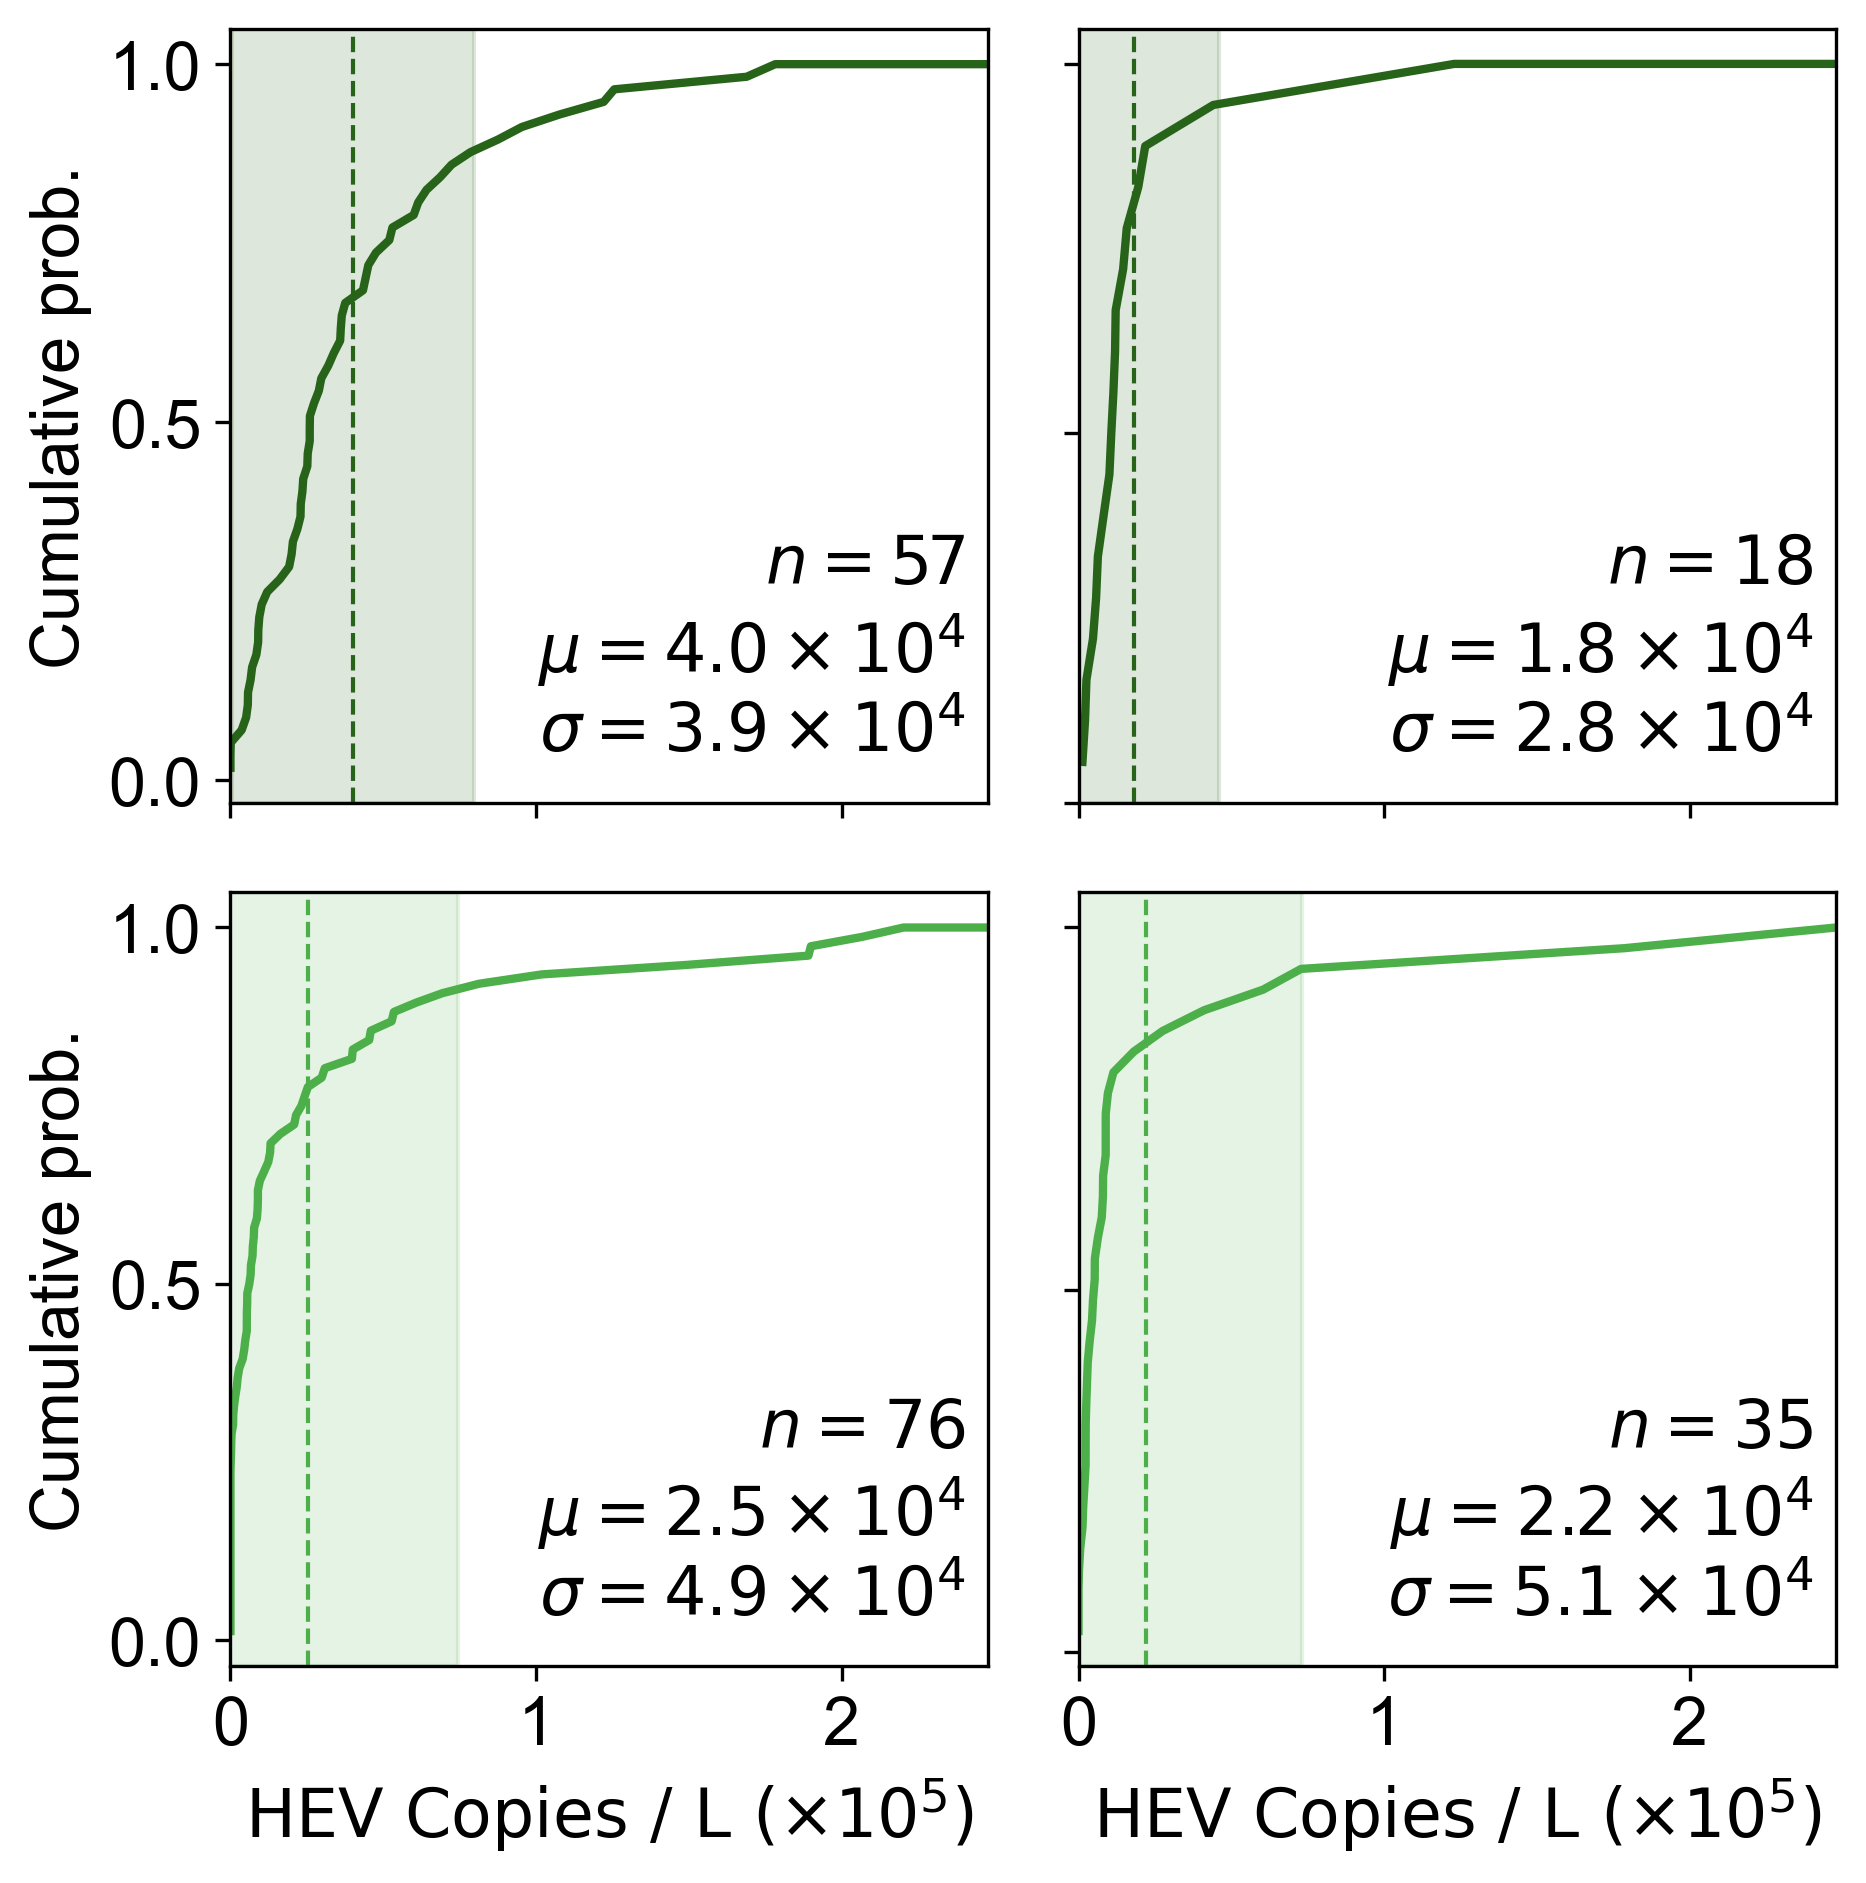

In [11]:
plt.style.use('default')
set_fontsize()

locs = ['24h Probe', 'Schmidbartlanger']
categories = ['Non-Emergency', 'Emergency']
color_map = {"24h Probe": darkgreen, "Schmidbartlanger": lightgreen}
x_min, x_max = obs['HEV_c'].min() / 1e5, obs['HEV_c'].max() / 1e5
x_grid = np.linspace(x_min, x_max, 200)

fig, axes = plt.subplots(figsize = (6.5,6.56), nrows=2, ncols=2, dpi=300)

for i, name in enumerate(locs):
    for j, cat in enumerate(categories):
        ax = axes[i, j]

        subset = obs[(obs['Name'] == name) & (obs['Category'] == cat)].copy()
        subset["HEV_c"] = subset["HEV_c"] / 1e5
        x = np.sort(subset['HEV_c'])
        y = np.arange(1, len(x) + 1) / len(x)
        x = np.append(x, x_max)
        y = np.append(y, 1.0)
        ax.plot(x, y, color=color_map.get(name, "black"), linewidth=2)
        #ax.plot(subset['HEV_c'], np.zeros_like(subset['HEV_c']), marker='|', linestyle='none', markersize=6, alpha=0.4, color = color_map.get(name, "black"))
        
        n = len(subset)
        mean = subset['HEV_c'].mean()
        sd = subset['HEV_c'].std(ddof=1)
        ax.axvline(mean, linestyle='--', linewidth = 1, color = color_map.get(name, "black") ) # show mean +/- 1 SD and label
        ax.axvspan(mean - sd, mean + sd, color=color_map.get(name, "black"), alpha=0.15)
        text_str = "\n".join([rf"$n = {n}$", rf"$\mu = {mean*10:.1f} \times 10^{4}$", rf"$\sigma = {sd*10:.1f} \times 10^{4}$"])
        ax.text(0.97, 0.05, text_str, transform=ax.transAxes, ha='right', va='bottom', fontsize=16, bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"))

        ax.set_title("")
        ax.set_yticks([0, 0.5, 1])

        if i == 0:
            ax.set_xlabel("")
            ax.set_xticklabels([])
            ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False)
        else:
            ax.set_xlabel(r"$\mathrm{HEV\ Copies\ / \ L\ ( \times 10^{5})}$")
            ax.ticklabel_format(axis='x', style='plain')

        if j == 1:
            ax.set_ylabel("")
            ax.set_yticklabels([])
            ax.tick_params(axis='y', which='both', left=True, right=False, labelleft=False)
        else:
            ax.set_ylabel("Cumulative prob.")

        ax.set_xlim(x_min, x_max)

# display_names = {'24h Probe': 'Gut Großlappen', 'Schmidbartlanger': 'Schmidbartlanger', 'Emergency': 'Lockdown', 'Non-Emergency': 'Non-Lockdown'}
# 
# for i, name in enumerate(locs):
#     axes[i, 0].annotate(display_names.get(name, name), xy=(-0.25, 0.5), xycoords='axes fraction',
#                         ha='right', va='center', rotation=90, fontsize=18)

plt.tight_layout()
plt.savefig(f"{plot_path}/dist-fits.png", dpi=300)
plt.show()

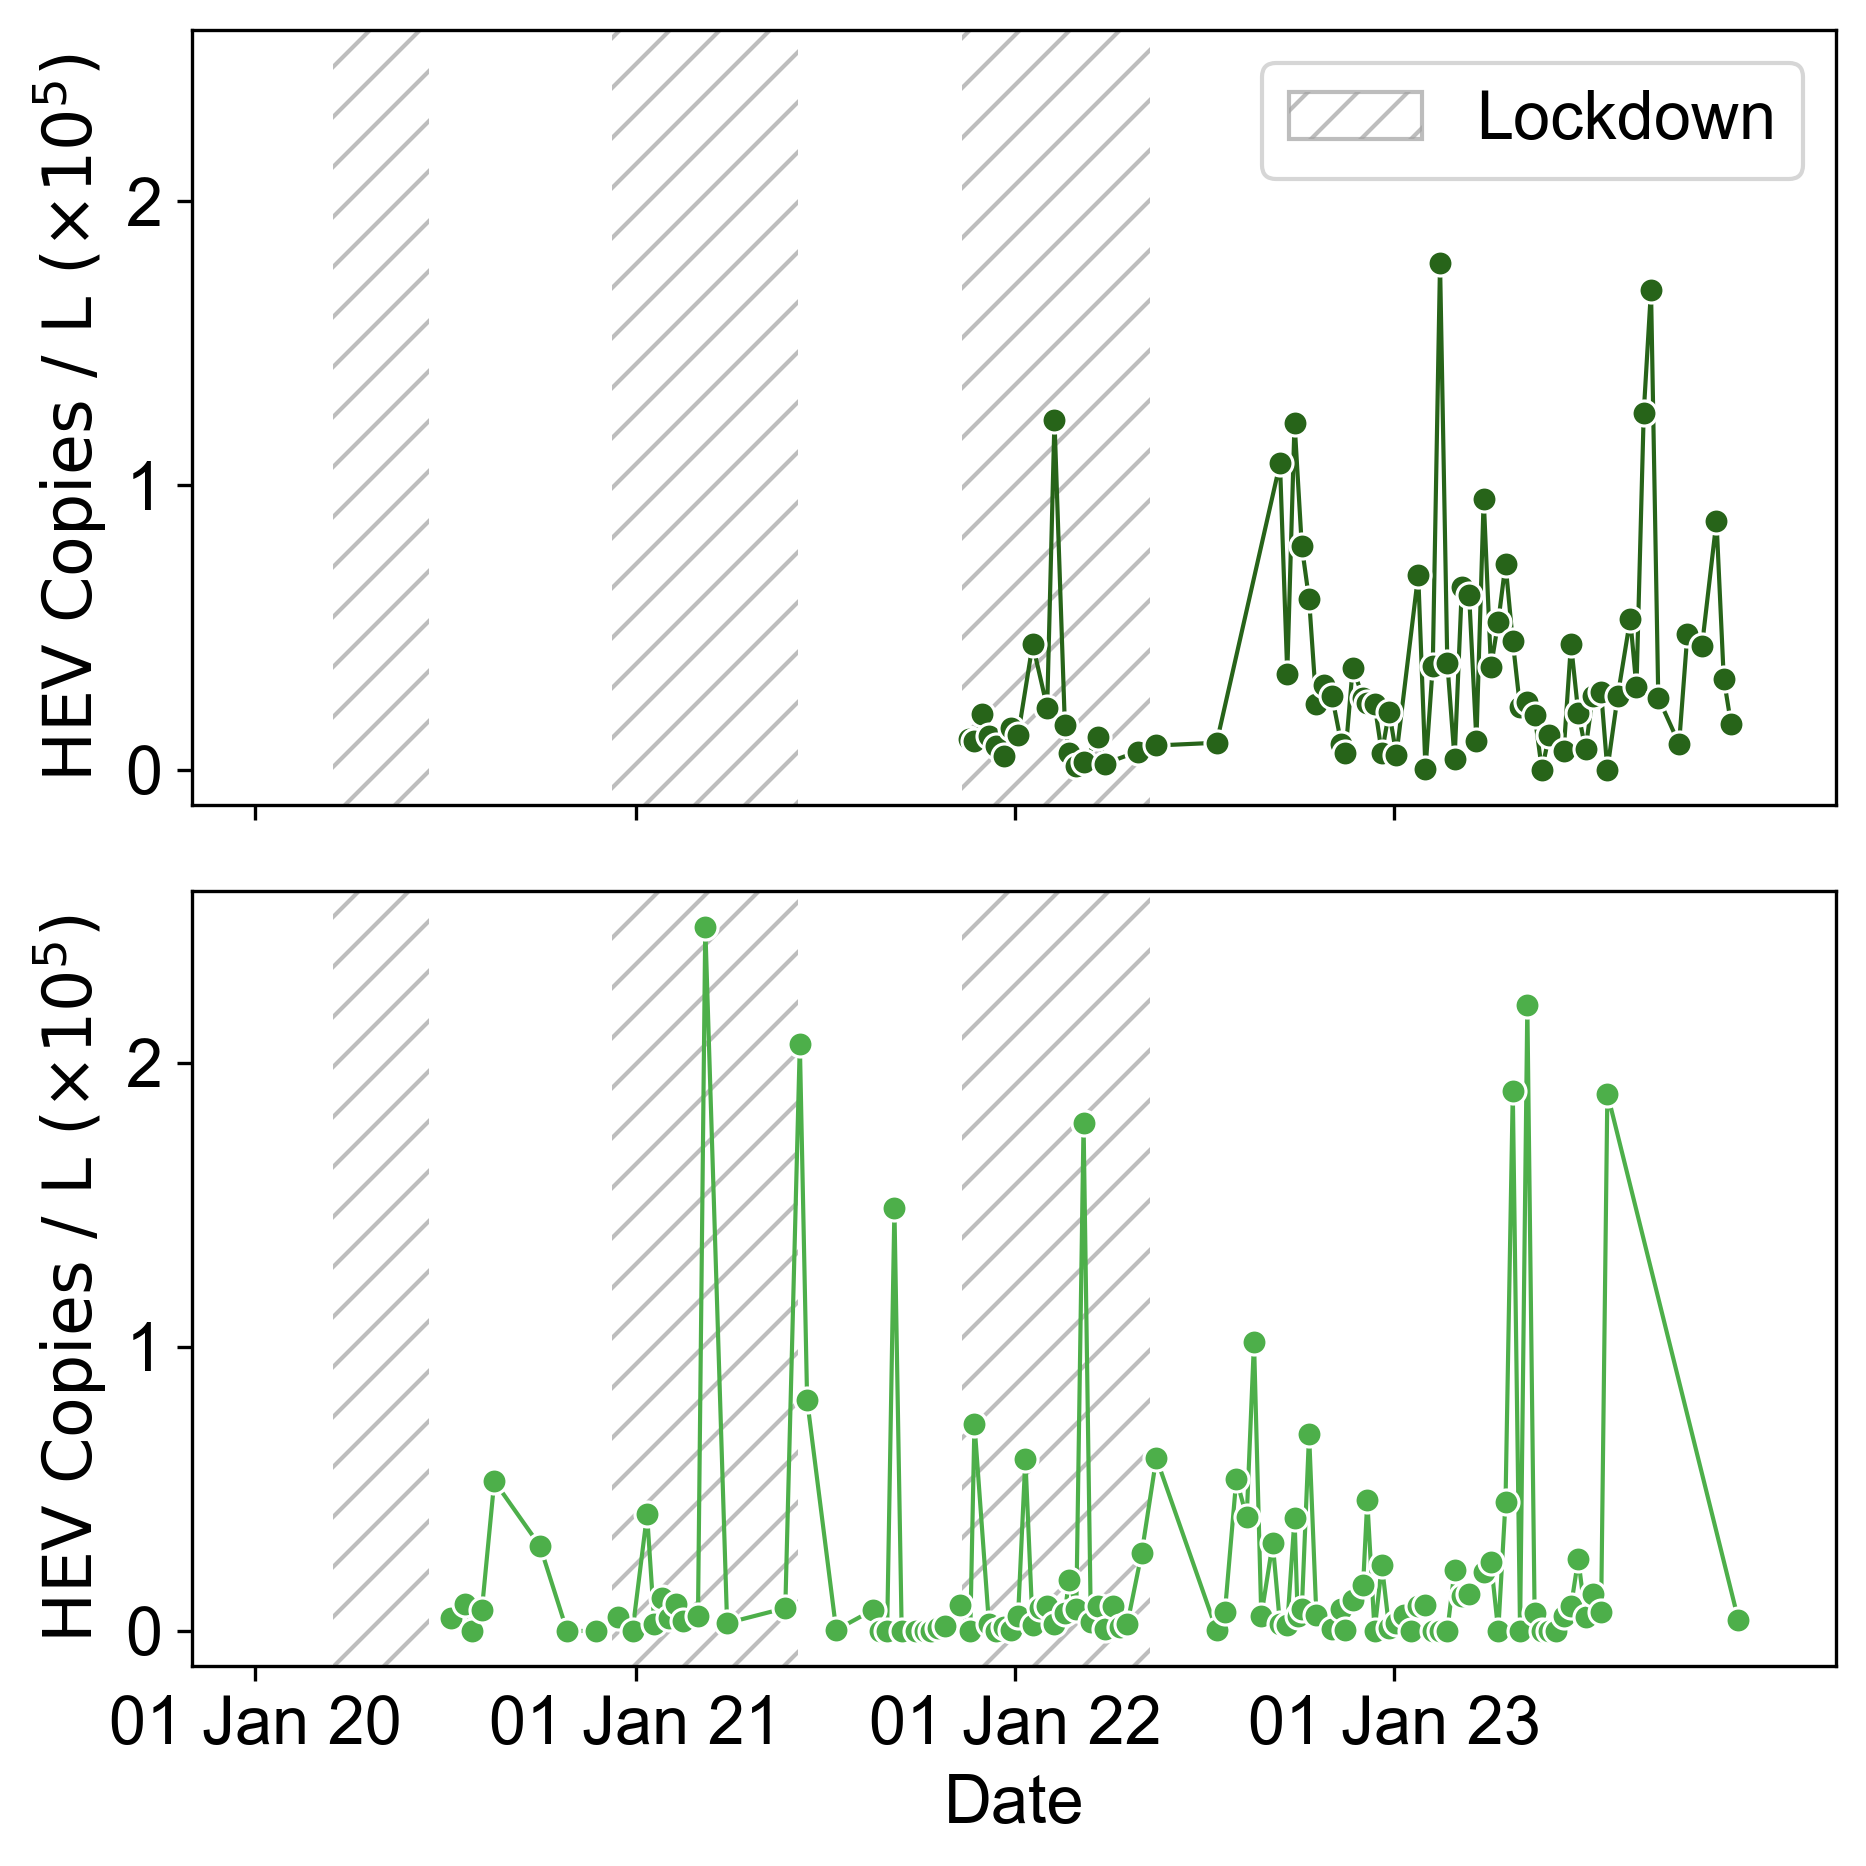

In [8]:
plt.style.use('default')
set_fontsize()

obs["HEV_c_scaled"] = obs["HEV_c"] / 1e5
obs_G = obs[(obs['Name'] == '24h Probe')]
obs_S = obs[(obs['Name'] == 'Schmidbartlanger')]

fig, axes = plt.subplots(figsize = (6.5,6.5), nrows=2, ncols=1, dpi=300, sharex = True, sharey = True)

sns.lineplot(data=obs_G, x="Date", y="HEV_c_scaled", ax=axes[0], color = color_map.get("24h Probe", "black"), marker="o", linewidth = 1, zorder=3)
axes[0].set_ylabel(r"$\mathrm{HEV\ Copies\ / \ L\ ( \times 10^{5})}$")
axes[0].yaxis.set_major_locator(MaxNLocator(nbins=3))
# axes[0].annotate("Gut Großlappen", xy=(-0.1, 0.5), xycoords='axes fraction', ha='right', va='center', rotation=90, fontsize=18)

sns.lineplot(data=obs_S, x="Date", y="HEV_c_scaled", ax=axes[1], color = color_map.get("Schmidbartlanger", "black"), linewidth = 1, marker="o", zorder=3)
axes[1].set_ylabel(r"$\mathrm{HEV\ Copies\ / \ L\ ( \times 10^{5})}$")
# axes[1].annotate("Schmidbartlanger", xy=(-0.1, 0.5), xycoords='axes fraction', ha='right', va='center', rotation=90, fontsize=18)
axes[1].yaxis.set_major_locator(MaxNLocator(nbins=3))
axes[1].set_xlabel("Date")
axes[1].set_xticks(pd.to_datetime(["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01"]))
axes[1].set_xlim(pd.Timestamp("2019-11-01"), pd.Timestamp("2024-03-01"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %y"))

lockdown_periods = [
    (pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-16")),
    (pd.Timestamp("2020-12-09"), pd.Timestamp("2021-06-06")),
    (pd.Timestamp("2021-11-11"), pd.Timestamp("2022-05-11"))
]

for ax in axes:
    for start, end in lockdown_periods:
        rect = mpatches.Rectangle((start, 0), width=end - start, height=1, transform=ax.get_xaxis_transform(), facecolor='none', edgecolor=medium_grey,
                                  alpha = 0.7, hatch='//', linewidth=0.0, zorder=-10)
        ax.add_patch(rect)

lockdown_patch = mpatches.Patch(facecolor='none', edgecolor=medium_grey, hatch='//', label='Lockdown', alpha=0.7)
axes[0].legend(handles=[lockdown_patch], loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig(f"{plot_path}/long-fits.png", dpi=300)
plt.show()